## Exploratory Data Analysis

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

df = pd.read_excel("D:/Mani/Docs/Projects/Flight_Price_Prediction/flight-price-prediction-mlops/data/raw/Flight_Dataset.xlsx")

print("Dataset shape: {}".format(df.shape))
display(df.head())

Dataset shape: (300153, 11)


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [4]:
print("========== DATASET INFORMATION ==========")
df.info()

print("\n========== NUMERICAL FEATURES ==========")
display(df.describe())

print("\n========== CATEGORICAL FEATURES ==========")

categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

display(df[categorical_columns].describe())

print("\n========== UNIQUE VALUES ==========")

for column in df.columns:
    print("{}: {}".format(column, df[column].nunique()))

========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  str    
 1   flight            300153 non-null  object 
 2   source_city       300153 non-null  str    
 3   departure_time    300153 non-null  str    
 4   stops             300153 non-null  str    
 5   arrival_time      300153 non-null  str    
 6   destination_city  300153 non-null  str    
 7   class             300153 non-null  str    
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(1), str(7)
memory usage: 25.2+ MB

========== NUMERICAL FEATURES ==========


,duration,days_left,price
count,300153.000000,300153.000000,300153.000000
mean,12.221021,26.004751,20889.660523
std,7.191997,13.561004,22697.767366
min,0.830000,1.000000,1105.000000
25%,6.830000,15.000000,4783.000000
50%,11.250000,26.000000,7425.000000
75%,16.170000,38.000000,42521.000000
max,49.830000,49.000000,123071.000000



========== CATEGORICAL FEATURES ==========


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666



========== UNIQUE VALUES ==========
airline: 6
flight: 1561
source_city: 6
departure_time: 6
stops: 3
arrival_time: 6
destination_city: 6
class: 2
duration: 476
days_left: 49
price: 12157


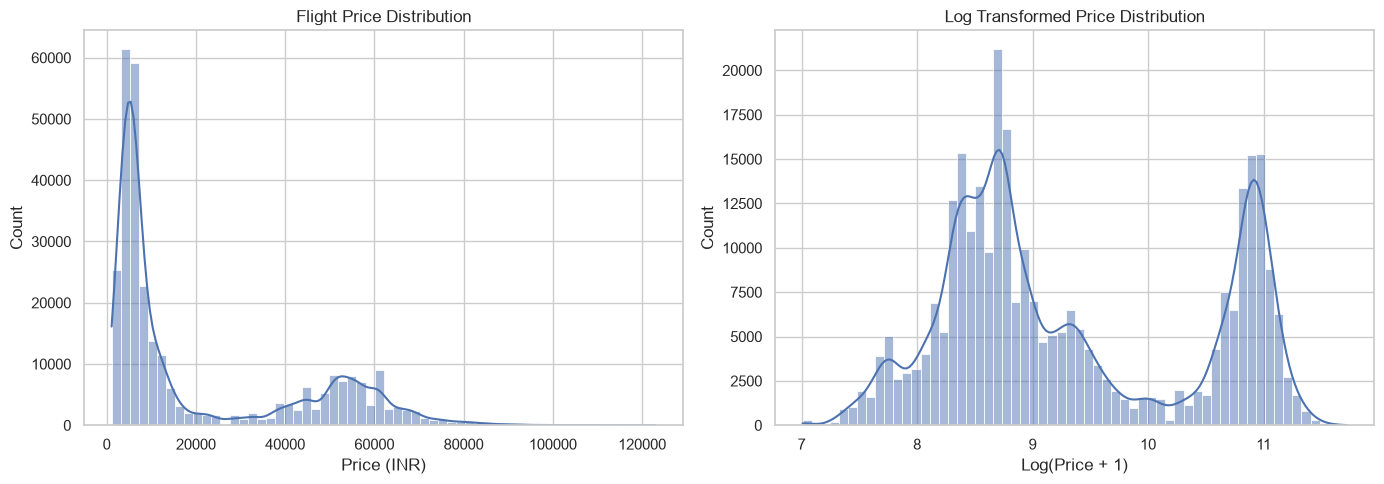

Price Skewness: 1.061377253206434
Price Kurtosis: -0.3962927186960775


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["price"],
    bins=60,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Flight Price Distribution")
axes[0].set_xlabel("Price (INR)")

sns.histplot(
    np.log1p(df["price"]),
    bins=60,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log Transformed Price Distribution")
axes[1].set_xlabel("Log(Price + 1)")

plt.tight_layout()
plt.show()

print("Price Skewness: {}".format(df["price"].skew()))
print("Price Kurtosis: {}".format(df["price"].kurtosis()))

,mean,median,count
airline,,,
Vistara,30396.536302,15543.0,127859
Air_India,23507.019112,11520.0,80892
SpiceJet,6179.278881,5654.0,9011
GO_FIRST,5652.007595,5336.0,23173
Indigo,5324.216303,4453.0,43120
AirAsia,4091.072742,3276.0,16098


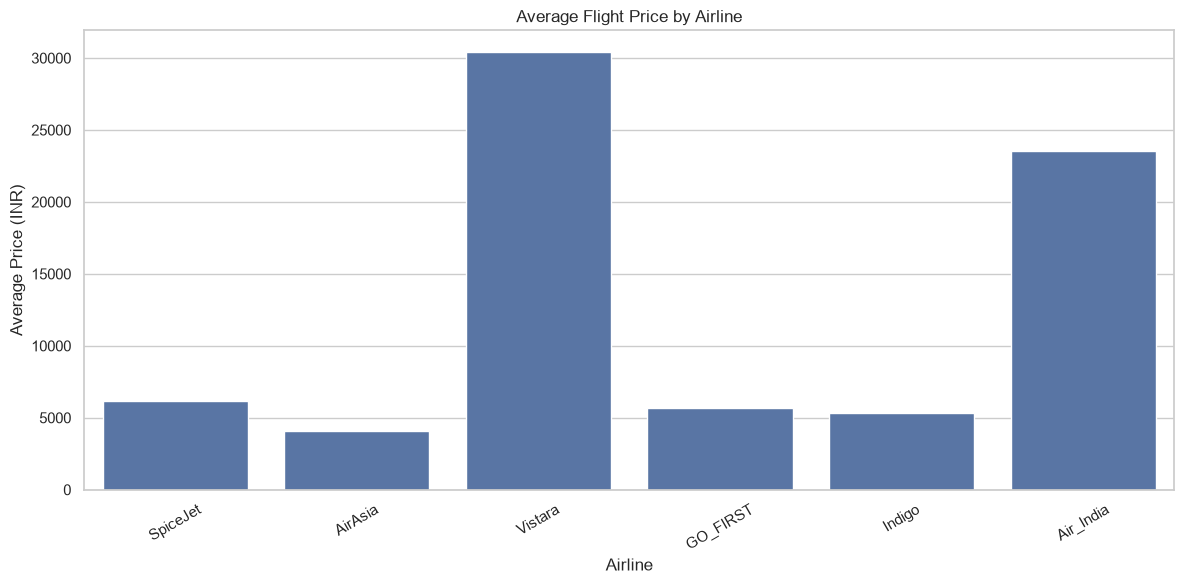

In [6]:
airline_prices = (
    df.groupby("airline")["price"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(airline_prices)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="airline",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price (INR)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

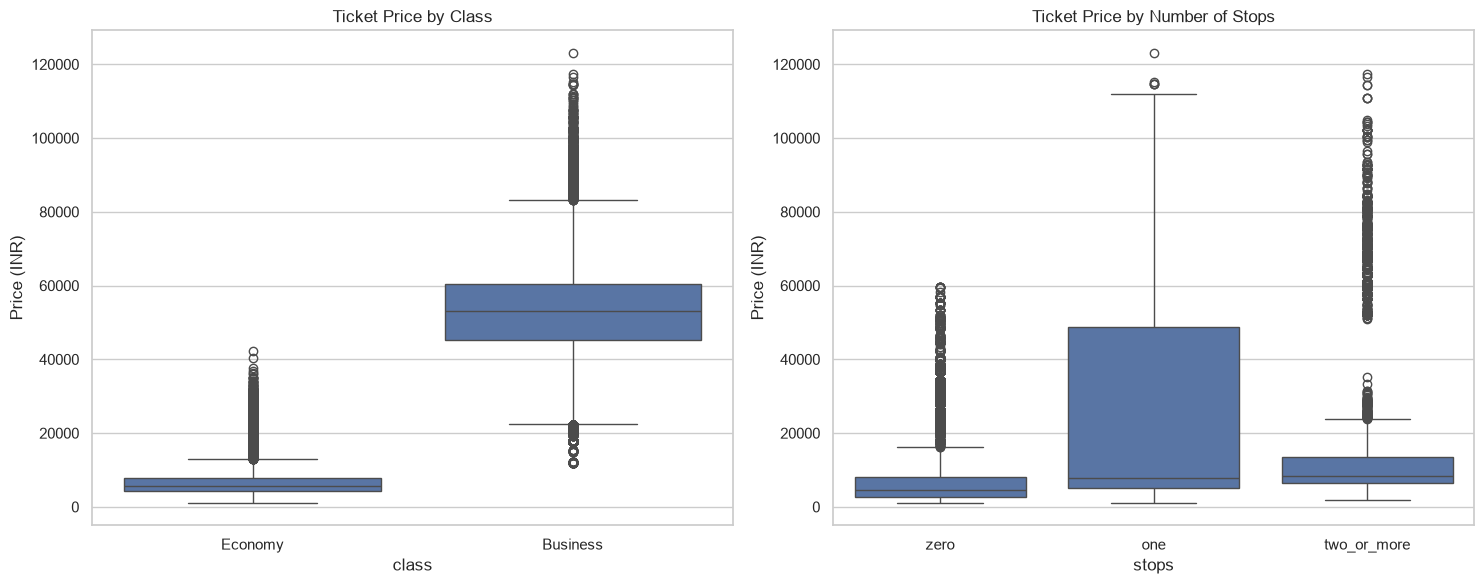


Average Price by Class:


,mean,median,count
class,,,
Business,52540.081124,53164.0,93487
Economy,6572.342383,5772.0,206666



Average Price by Stops:


,mean,median,count
stops,,,
one,22900.992482,7959.0,250863
two_or_more,14113.450775,8307.0,13286
zero,9375.938535,4499.0,36004


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=df,
    x="class",
    y="price",
    ax=axes[0]
)

axes[0].set_title("Ticket Price by Class")
axes[0].set_ylabel("Price (INR)")

sns.boxplot(
    data=df,
    x="stops",
    y="price",
    ax=axes[1]
)

axes[1].set_title("Ticket Price by Number of Stops")
axes[1].set_ylabel("Price (INR)")

plt.tight_layout()
plt.show()

print("\nAverage Price by Class:")
display(df.groupby("class")["price"].agg(["mean", "median", "count"]))

print("\nAverage Price by Stops:")
display(df.groupby("stops")["price"].agg(["mean", "median", "count"]))

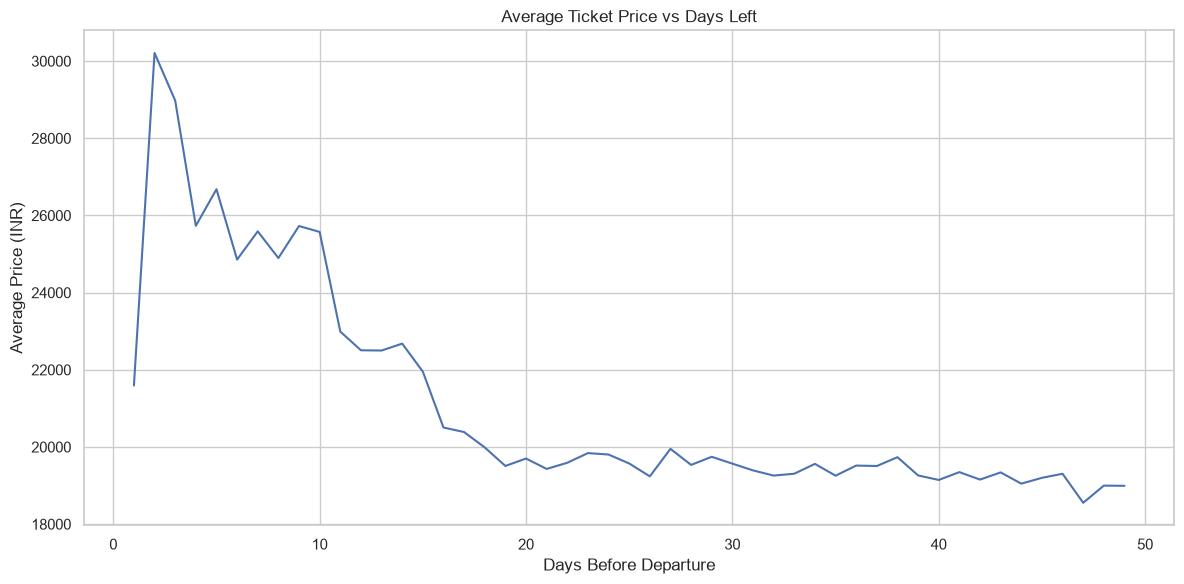

In [8]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="days_left",
    y="price",
    errorbar=None
)

plt.title("Average Ticket Price vs Days Left")
plt.xlabel("Days Before Departure")
plt.ylabel("Average Price (INR)")

plt.tight_layout()
plt.show()

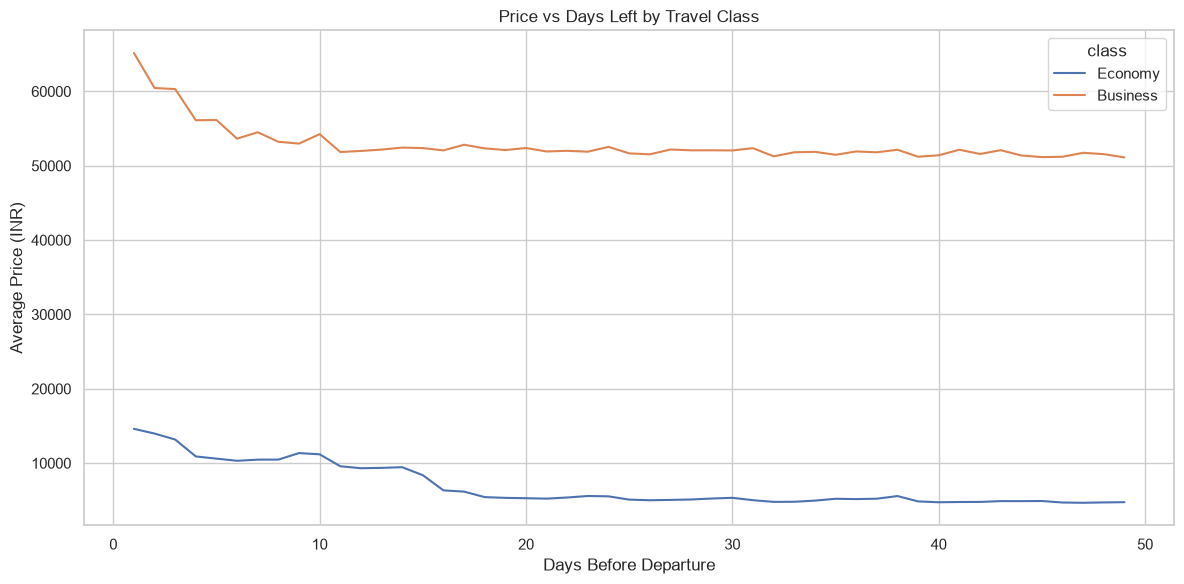

In [9]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="days_left",
    y="price",
    hue="class",
    errorbar=None
)

plt.title("Price vs Days Left by Travel Class")
plt.xlabel("Days Before Departure")
plt.ylabel("Average Price (INR)")

plt.tight_layout()
plt.show()

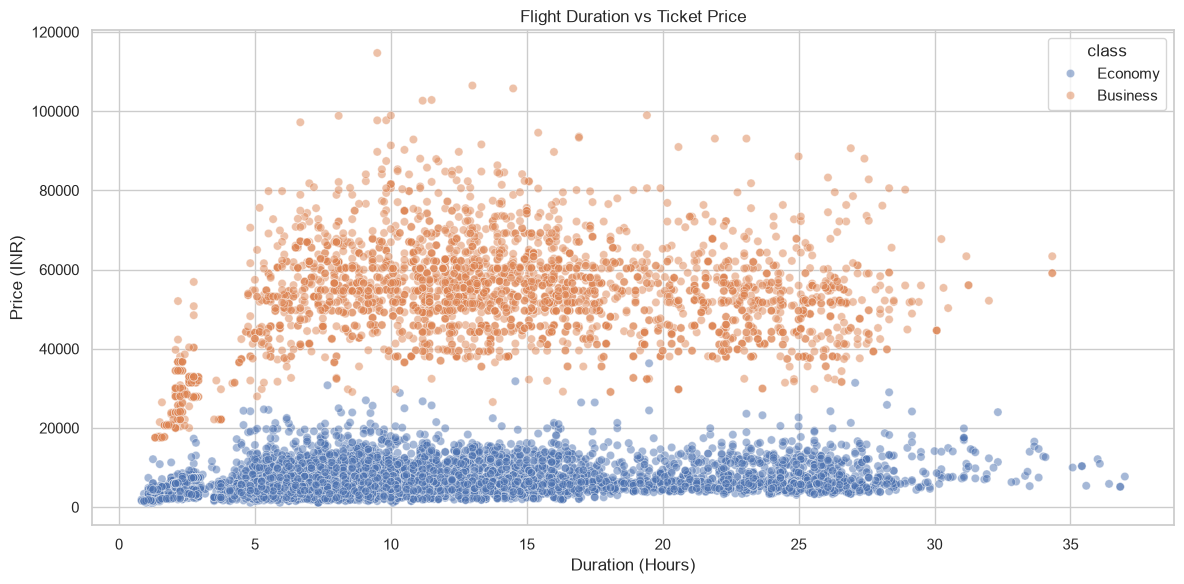

In [10]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x="duration",
    y="price",
    hue="class",
    alpha=0.5
)

plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration (Hours)")
plt.ylabel("Price (INR)")

plt.tight_layout()
plt.show()

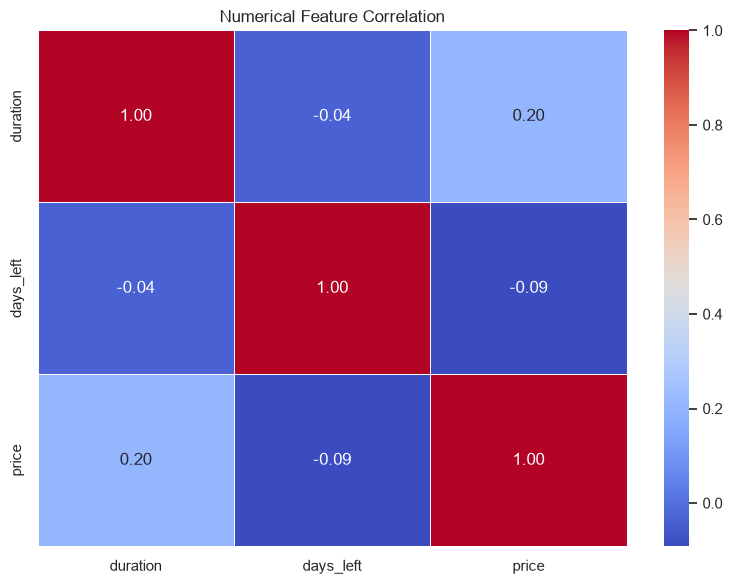

In [11]:
numerical_columns = [
    "duration",
    "days_left",
    "price"
]

correlation = df[numerical_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Feature Correlation")

plt.tight_layout()
plt.show()

In [15]:
print(correlation)

           duration  days_left     price
duration   1.000000  -0.039157  0.204222
days_left -0.039157   1.000000 -0.091949
price      0.204222  -0.091949  1.000000


### Data Quality Analysis

In [12]:
categorical_columns = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "class"
]

for column in categorical_columns:

    print("\n{}:".format(column))

    print(
        sorted(df[column].astype(str).unique().tolist())
    )


airline:
['AirAsia', 'Air_India', 'GO_FIRST', 'Indigo', 'SpiceJet', 'Vistara']

source_city:
['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']

departure_time:
['Afternoon', 'Early_Morning', 'Evening', 'Late_Night', 'Morning', 'Night']

stops:
['one', 'two_or_more', 'zero']

arrival_time:
['Afternoon', 'Early_Morning', 'Evening', 'Late_Night', 'Morning', 'Night']

destination_city:
['Bangalore', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai']

class:
['Business', 'Economy']


In [13]:
print("========== NUMERICAL QUALITY CHECK ==========")

print("Invalid durations:", (df["duration"] <= 0).sum())

print("Invalid days left:", (df["days_left"] <= 0).sum())

print("Invalid prices:", (df["price"] <= 0).sum())

print(
    "Same source and destination:",
    (df["source_city"] == df["destination_city"]).sum()
)

print(
    "Infinite numerical values:",
    np.isinf(
        df[["duration", "days_left", "price"]].to_numpy()
    ).sum()
)

========== NUMERICAL QUALITY CHECK ==========
Invalid durations: 0
Invalid days left: 0
Invalid prices: 0
Same source and destination: 0
Infinite numerical values: 0


In [14]:
def calculate_outliers(data, column):

    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - (1.5 * iqr)
    upper_limit = q3 + (1.5 * iqr)

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    return lower_limit, upper_limit, len(outliers)


for travel_class in df["class"].unique():

    class_data = df[df["class"] == travel_class]

    lower, upper, count = calculate_outliers(
        class_data,
        "price"
    )

    print("\nClass: {}".format(travel_class))
    print("Lower limit: {:.2f}".format(lower))
    print("Upper limit: {:.2f}".format(upper))
    print("Potential outliers: {}".format(count))
    print(
        "Outlier percentage: {:.2f}%".format(
            count / len(class_data) * 100
        )
    )


Class: Economy
Lower limit: -1186.50
Upper limit: 13105.50
Potential outliers: 13749
Outlier percentage: 6.65%

Class: Business
Lower limit: 22368.50
Upper limit: 83212.50
Potential outliers: 3650
Outlier percentage: 3.90%


,airline,class,mean,median,count
6,Vistara,Business,55477.027777,56588.0,60589
1,Air_India,Business,47131.039212,49613.0,32898
7,Vistara,Economy,7806.943645,6461.0,67270
2,Air_India,Economy,7313.682169,6082.0,47994
5,SpiceJet,Economy,6179.278881,5654.0,9011
3,GO_FIRST,Economy,5652.007595,5336.0,23173
4,Indigo,Economy,5324.216303,4453.0,43120
0,AirAsia,Economy,4091.072742,3276.0,16098


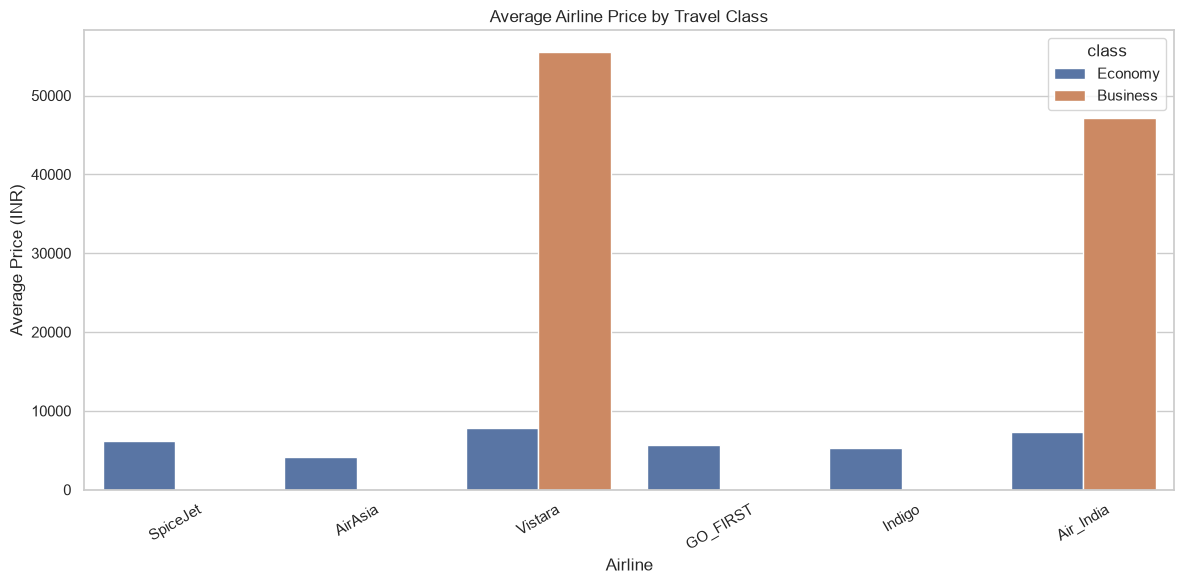

In [17]:
#  Airline Pricing  by Class
airline_class_prices = (
    df.groupby(["airline", "class"])["price"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(
    airline_class_prices.sort_values(
        ["class", "mean"],
        ascending=[True, False]
    )
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="airline",
    y="price",
    hue="class",
    estimator="mean",
    errorbar=None
)

plt.title("Average Airline Price by Travel Class")
plt.xlabel("Airline")
plt.ylabel("Average Price (INR)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
# Source and destination route pricing

route_prices = (
    df.groupby(["source_city", "destination_city"])["price"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

route_prices = route_prices.sort_values(
    "mean",
    ascending=False
)

display(route_prices.head(15))

,source_city,destination_city,mean,median,count
5,Chennai,Bangalore,25081.850454,10469.0,6493
21,Kolkata,Chennai,23660.361040,8589.0,6653
3,Bangalore,Kolkata,23500.061229,8112.0,10028
0,Bangalore,Chennai,23321.850078,9241.0,6410
25,Mumbai,Bangalore,23147.873807,7192.0,12885
4,Bangalore,Mumbai,23128.618672,7113.0,12939
26,Mumbai,Chennai,22781.899112,8148.0,10130
9,Chennai,Mumbai,22765.849647,8233.0,9338
20,Kolkata,Bangalore,22744.808428,8111.0,9824
8,Chennai,Kolkata,22669.932407,8394.0,6983


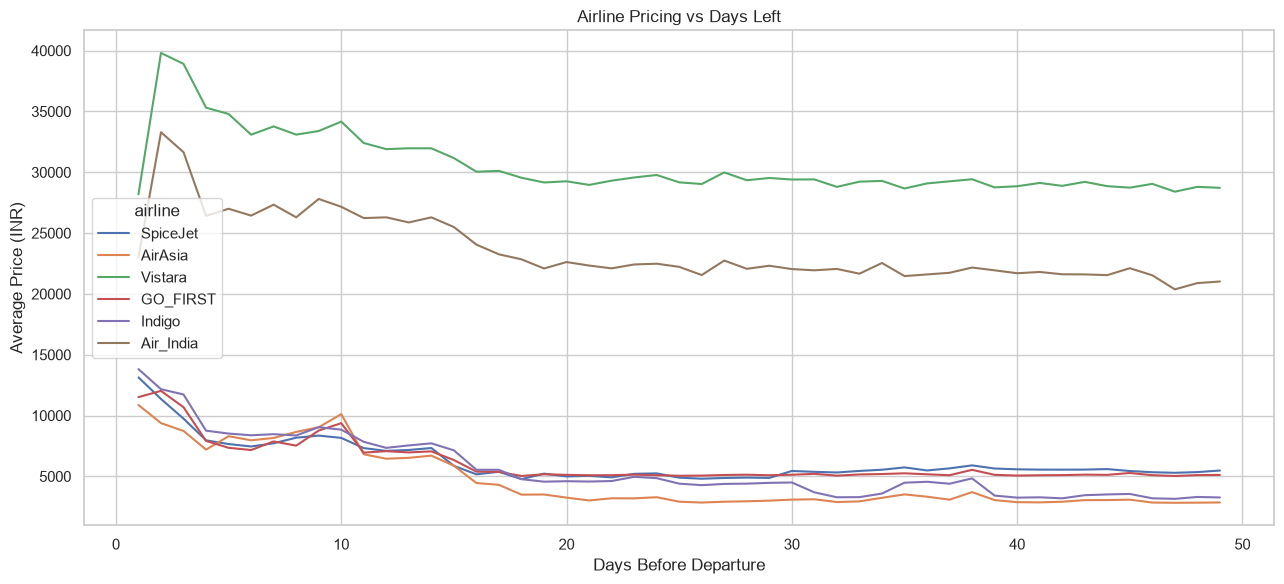

In [19]:
# Airline and booking lead-time relationship

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=df,
    x="days_left",
    y="price",
    hue="airline",
    errorbar=None
)

plt.title("Airline Pricing vs Days Left")
plt.xlabel("Days Before Departure")
plt.ylabel("Average Price (INR)")
plt.tight_layout()
plt.show()

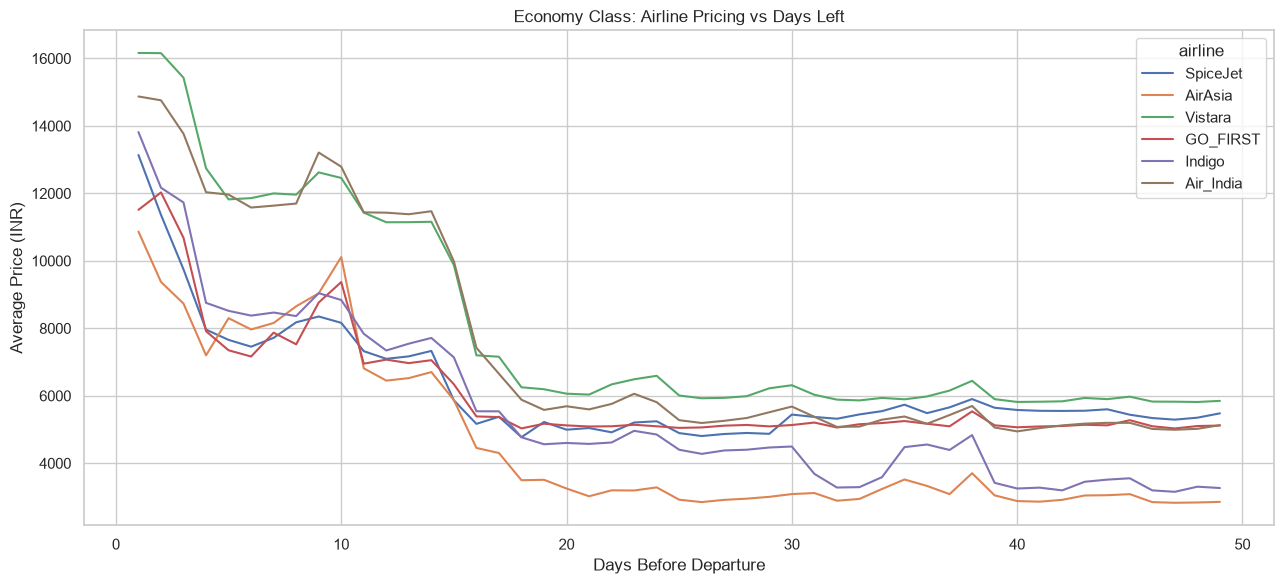

In [20]:
economy_df = df[df["class"] == "Economy"]

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=economy_df,
    x="days_left",
    y="price",
    hue="airline",
    errorbar=None
)

plt.title("Economy Class: Airline Pricing vs Days Left")
plt.xlabel("Days Before Departure")
plt.ylabel("Average Price (INR)")

plt.tight_layout()
plt.show()

In [21]:
economy_df.describe()

,duration,days_left,price
count,206666.000000,206666.000000,206666.000000
mean,11.550060,26.123673,6572.342383
std,7.241284,13.529610,3743.519517
min,0.830000,1.000000,1105.000000
25%,6.250000,15.000000,4173.000000
50%,10.170000,26.000000,5772.000000
75%,15.250000,38.000000,7746.000000
max,49.830000,49.000000,42349.000000


In [22]:
route_prices = (
    df.groupby(
        ["source_city", "destination_city"]
    )["price"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

route_prices = route_prices.sort_values(
    "mean",
    ascending=False
)

display(route_prices.head(20))

,source_city,destination_city,mean,median,count
5,Chennai,Bangalore,25081.850454,10469.0,6493
21,Kolkata,Chennai,23660.361040,8589.0,6653
3,Bangalore,Kolkata,23500.061229,8112.0,10028
0,Bangalore,Chennai,23321.850078,9241.0,6410
25,Mumbai,Bangalore,23147.873807,7192.0,12885
4,Bangalore,Mumbai,23128.618672,7113.0,12939
26,Mumbai,Chennai,22781.899112,8148.0,10130
9,Chennai,Mumbai,22765.849647,8233.0,9338
20,Kolkata,Bangalore,22744.808428,8111.0,9824
8,Chennai,Kolkata,22669.932407,8394.0,6983


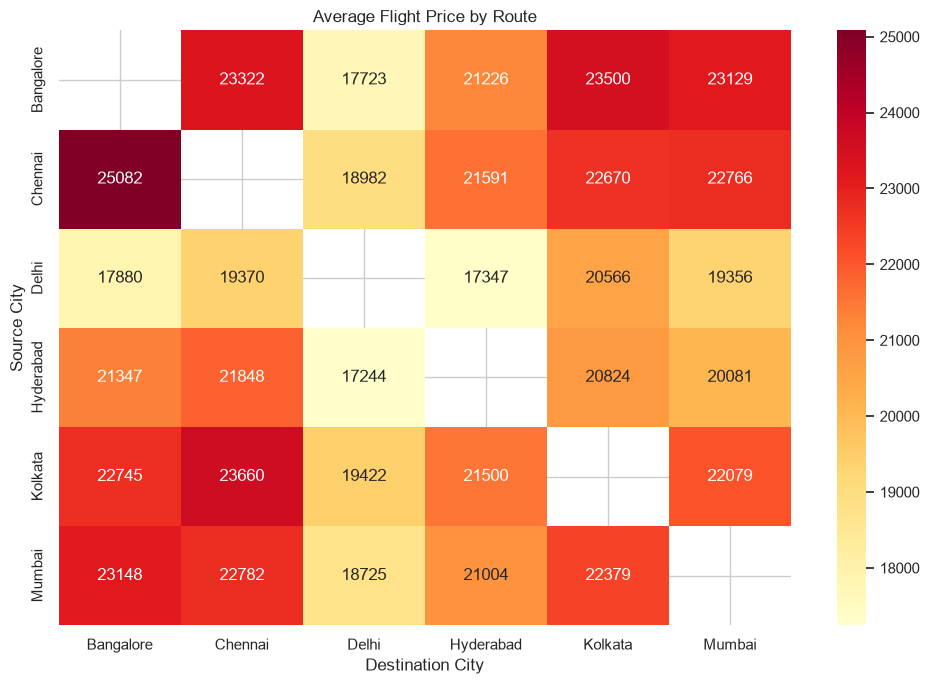

In [23]:
route_matrix = df.pivot_table(
    values="price",
    index="source_city",
    columns="destination_city",
    aggfunc="mean"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    route_matrix,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.title("Average Flight Price by Route")
plt.xlabel("Destination City")
plt.ylabel("Source City")

plt.tight_layout()
plt.show()

In [24]:
print(route_matrix)

destination_city     Bangalore       Chennai         Delhi     Hyderabad  \
source_city                                                                
Bangalore                  NaN  23321.850078  17723.313972  21226.121192   
Chennai           25081.850454           NaN  18981.863948  21591.345404   
Delhi             17880.216315  19369.881354           NaN  17347.288379   
Hyderabad         21347.177998  21848.065989  17243.945685           NaN   
Kolkata           22744.808428  23660.361040  19422.354559  21500.011397   
Mumbai            23147.873807  22781.899112  18725.320008  21004.046705   

destination_city       Kolkata        Mumbai  
source_city                                   
Bangalore         23500.061229  23128.618672  
Chennai           22669.932407  22765.849647  
Delhi             20566.409418  19355.829812  
Hyderabad         20823.893201  20080.865759  
Kolkata                    NaN  22078.883579  
Mumbai            22379.146723           NaN  


In [25]:
df["route"] = (
    df["source_city"] + "_to_" + df["destination_city"]
)